# Лабораторна робота №3: TF-IDF зважені ембеддинги для детекції AI-текстів

**Мета:** навчити FastText на корпусі текстів, зібрати з векторів слів вектор документа двома способами
(звичайне середнє і середнє з вагами TF-IDF), а потім порівняти SVM, Logistic Regression і KNN у задачі
"текст написала людина чи AI". Також подивимось на геометрію отриманих векторів через t-SNE.

**Датасет:** AI vs Human Text Classification Dataset 2026 (Kaggle), два класи - `human` і `ai`.

## 0. Бібліотеки

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import spacy
from gensim.models import FastText
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (f1_score, accuracy_score, balanced_accuracy_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.manifold import TSNE

---
## 1. Етап 1. Завантаження та первинний аналіз даних

In [2]:
df = pd.read_csv('data/ai_vs_human_text_2026.csv')
print(df.shape)
df.head()

(2000, 9)


,text_id,label,source_model,domain,text_content,topic_hint,word_count,avg_sentence_length,generation_method
0,TXT_0001,human,human,social,can we talk about gene editing ethics for a se...,gene editing ethics,27,13.5,template+human_variation
1,TXT_0002,human,human,social,update on election integrity concerns: it's co...,election integrity concerns,20,10.0,template+human_variation
2,TXT_0003,ai,gemini-2.0,news,Analysts are closely watching developments rel...,climate change adaptation strategies,39,13.0,style_simulation
3,TXT_0004,human,human,academic,This paper examines genomic research breakthro...,genomic research breakthroughs,49,16.3,template+human_variation
4,TXT_0005,ai,gpt-4o,academic,Existing literature on student debt crisis has...,student debt crisis,42,10.8,style_simulation


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   text_id              2000 non-null   str    
 1   label                2000 non-null   str    
 2   source_model         2000 non-null   str    
 3   domain               2000 non-null   str    
 4   text_content         2000 non-null   str    
 5   topic_hint           2000 non-null   str    
 6   word_count           2000 non-null   int64  
 7   avg_sentence_length  2000 non-null   float64
 8   generation_method    2000 non-null   str    
dtypes: float64(1), int64(1), str(7)
memory usage: 140.8 KB


У таблиці 9 колонок, але для задачі потрібні тільки сам текст (`text_content`) і мітка (`label`).
Колонки `source_model` і `generation_method` прямо кажуть, хто писав текст, тому брати їх як ознаки не можна,
інакше модель просто "підгляне" відповідь. `word_count` і `avg_sentence_length` теж не беремо: задача в тому,
щоб класифікувати саме за ембеддингами.

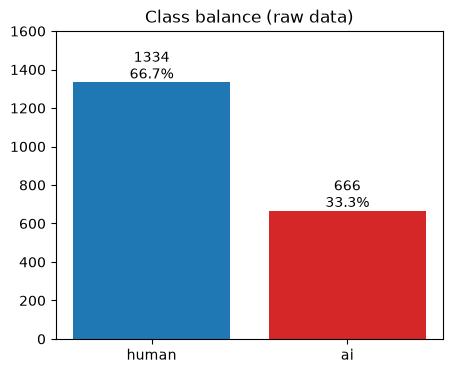

In [4]:
df = df[['text_content', 'label']].rename(columns={'text_content': 'text'})
df['y'] = (df['label'] == 'ai').astype(int)  # 1 = ai, 0 = human

counts = df['label'].value_counts()
plt.figure(figsize=(5, 4))
plt.bar(counts.index, counts.values, color=['tab:blue', 'tab:red'])
for i, value in enumerate(counts.values):
    plt.text(i, value + 20, f'{value}\n{value / len(df):.1%}', ha='center')
plt.ylim(0, counts.max() * 1.2)
plt.title('Class balance (raw data)')
plt.show()

### Пошук артефактів

In [5]:
df['n_words'] = df['text'].str.split().str.len()
print('Missing values:', df.isna().sum().sum())
print('Empty texts:', (df['text'].str.strip() == '').sum())
print('Texts shorter than 5 words:', (df['n_words'] < 5).sum())
print('Duplicated texts:', df['text'].duplicated().sum())
print('Texts that appear with both labels:', (df.groupby('text')['label'].nunique() > 1).sum())

Missing values: 0
Empty texts: 0
Texts shorter than 5 words: 0
Duplicated texts: 1034
Texts that appear with both labels: 0


In [6]:
# the most repeated texts
df['text'].value_counts().head(3)

text
Recent scholarship on gig economy labor rights has largely focused on surface-level manifestations while neglecting underlying structural determinants. This article challenges dominant assumptions and calls for a more nuanced approach that integrates interdisciplinary perspectives. Implications for policy and practice are discussed in the concluding section.    11
The theoretical underpinnings of autonomous vehicle safety have evolved considerably over the past two decades. What began as a niche area of inquiry has grown into a robust field with competing schools of thought. This review synthesizes key debates and identifies gaps that warrant further empirical investigation.                                                 9
A new study published today reveals that algorithmic bias in hiring. Researchers from several universities collaborated on the findings, which have been met with mixed reactions from the scientific community. The lead researcher said the results were 'unexpecte

**Висновок.** Пропусків, порожніх і дуже коротких текстів немає. Зате є величезна проблема: **1 034 тексти з 2 000 -
дублікати**. Датасет, схоже, зібраний із шаблонів, і деякі тексти повторюються до 11 разів. Якщо дублікати
залишити, однаковий текст може потрапити і в train, і в test, і метрики будуть завищені (модель просто
"пам'ятає" текст). Тому залишаємо по одній копії кожного тексту. Конфліктних текстів (однаковий текст з різними
мітками) немає.

In [7]:
df = df.drop_duplicates('text').reset_index(drop=True)
print('Shape after dropping duplicates:', df.shape)
print(df['label'].value_counts())
print((df['label'].value_counts(normalize=True)).round(3))

Shape after dropping duplicates: (966, 4)
label
human    579
ai       387
Name: count, dtype: int64
label
human    0.599
ai       0.401
Name: proportion, dtype: float64


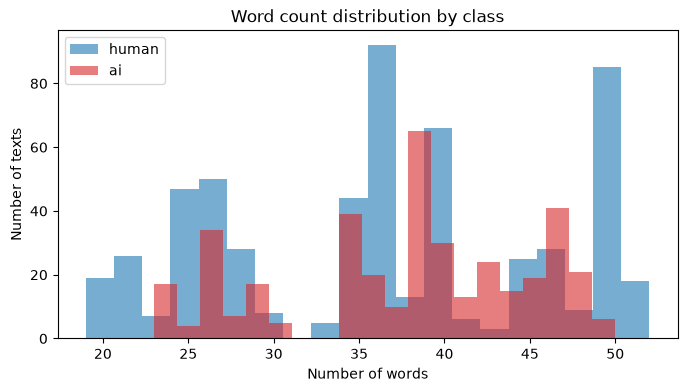

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
ai,387.0,37.9,7.0,23.0,35.0,39.0,44.0,50.0
human,579.0,36.3,9.4,19.0,27.0,36.0,44.0,52.0


In [8]:
plt.figure(figsize=(8, 4))
for label, color in [('human', 'tab:blue'), ('ai', 'tab:red')]:
    plt.hist(df.loc[df['label'] == label, 'n_words'], bins=20, alpha=0.6, label=label, color=color)
plt.xlabel('Number of words')
plt.ylabel('Number of texts')
plt.title('Word count distribution by class')
plt.legend()
plt.show()

df.groupby('label')['n_words'].describe().round(1)

**Висновок.** Після чистки маємо 966 унікальних текстів: 579 human (60%) і 387 ai (40%). Дисбаланс помірний,
тому крім Accuracy дивимось на F1 (macro) і Balanced Accuracy. Усі тексти короткі (приблизно 20-50 слів).
За довжиною класи помітно не відрізняються, тож одна довжина тексту клас не видасть.

---
## 2. Етап 2. Попередня обробка тексту (spaCy)

Для кожного токена: лишаємо тільки слова з букв (`is_alpha`), викидаємо стоп-слова, беремо лему і переводимо
в нижній регістр. Щоб було швидше, використовуємо `nlp.pipe()` з батчами і вимикаємо `parser` і `ner`:
для лематизації вони не потрібні.

In [9]:
nlp = spacy.load('en_core_web_sm', disable=['parser', 'ner'])

def preprocess_docs(texts):
    corpus = []
    for doc in nlp.pipe(texts, batch_size=64):
        tokens = []
        for token in doc:
            if token.is_alpha and not token.is_stop:
                tokens.append(token.lemma_.lower())
        corpus.append(tokens)
    return corpus

corpus = preprocess_docs(df['text'])
df['tokens'] = corpus

for i in [0, 2]:
    print('Original: ', df['text'][i])
    print('Processed:', df['tokens'][i])
    print()

Original:  can we talk about gene editing ethics for a sec because i feel like people are completely missing the point here. this is bigger than most realize
Processed: ['talk', 'gene', 'edit', 'ethic', 'sec', 'feel', 'like', 'people', 'completely', 'miss', 'point', 'big', 'realize']

Original:  Analysts are closely watching developments related to climate change adaptation strategies, noting that recent events mark a potential turning point. The situation underscores long-standing structural issues that have resisted easy solutions. Observers remain cautiously optimistic about prospects for reform.
Processed: ['analyst', 'closely', 'watch', 'development', 'relate', 'climate', 'change', 'adaptation', 'strategy', 'note', 'recent', 'event', 'mark', 'potential', 'turning', 'point', 'situation', 'underscore', 'long', 'stand', 'structural', 'issue', 'resist', 'easy', 'solution', 'observer', 'remain', 'cautiously', 'optimistic', 'prospect', 'reform']



In [10]:
vocab = {t for tokens in corpus for t in tokens}
print('Vocabulary size:', len(vocab))
print('Average tokens per document:', round(np.mean([len(t) for t in corpus]), 1))
print('Documents without tokens:', sum(len(t) == 0 for t in corpus))

Vocabulary size: 510
Average tokens per document: 22.0
Documents without tokens: 0


---
## 3. Етап 3. Навчання FastText

FastText вчить вектори не тільки для слів, а й для символьних n-грам, тому вектор можна отримати навіть для
слова, якого не було в корпусі.

In [11]:
model = FastText(
    sentences=corpus,
    vector_size=100,
    window=5,
    min_count=2,
    sg=1,
    workers=1,  # with several threads the result changes from run to run
    seed=42
)
print('Words in FastText vocabulary:', len(model.wv.key_to_index))

Words in FastText vocabulary: 508


In [12]:
# quick sanity check: nearest words
for word in ['study', 'policy', 'think']:
    print(word, '->', [w for w, _ in model.wv.most_similar(word, topn=5)])

# a word that is not in the corpus still gets a vector from its n-grams
oov = 'researchability'
print(oov, 'in vocabulary:', oov in model.wv.key_to_index, '| vector:', model.wv[oov][:4].round(3))

study -> ['publish', 'analyze', 'contribute', 'dataset', 'case']
policy -> ['policymaker', 'change', 'nuclear', 'discuss', 'necessary']
think -> ['happy', 'help', 'thing', 'conversation', 'well']
researchability in vocabulary: False | vector: [-0.19   0.498 -0.134  0.298]


Корпус маленький (менше тисячі коротких текстів), тому сусіди слів не завжди дуже "розумні", але загалом
слова з однієї теми опиняються поруч.

---
## 4. Етап 4. Векторизація документів

1. **Mean Pooling** - просто середнє векторів усіх слів документа.
2. **TF-IDF Weighted Mean** - зважене середнє, де вага слова - його TF-IDF у цьому документі. Слова, які трапляються
   майже в усіх документах, отримують малу вагу, а рідкісні - більшу.

TF-IDF рахуємо по тих самих токенах після spaCy (тому `analyzer` просто повертає список токенів).

In [13]:
tfidf = TfidfVectorizer(analyzer=lambda tokens: tokens)
tfidf_matrix = tfidf.fit_transform(df['tokens'])
tfidf_vocab = tfidf.get_feature_names_out()
print('TF-IDF matrix:', tfidf_matrix.shape)

def doc_tfidf_scores(i):
    row = tfidf_matrix[i]
    return dict(zip(tfidf_vocab[row.indices], row.data))

TF-IDF matrix: (966, 510)


In [14]:
def mean_pooling(tokens, model):
    vectors = [model.wv[t] for t in tokens if t in model.wv]
    if not vectors:
        return np.zeros(model.vector_size)
    return np.mean(vectors, axis=0)

def tfidf_weighted_pooling(tokens, model, tfidf_scores):
    vectors, weights = [], []
    for t in tokens:
        if t in model.wv and t in tfidf_scores:
            vectors.append(model.wv[t])
            weights.append(tfidf_scores[t])
    if not vectors:
        return np.zeros(model.vector_size)
    weights = np.array(weights)
    weights /= weights.sum()
    return np.average(vectors, axis=0, weights=weights)

X_mean = np.array([mean_pooling(tokens, model) for tokens in df['tokens']])
X_tfidf = np.array([tfidf_weighted_pooling(tokens, model, doc_tfidf_scores(i))
                    for i, tokens in enumerate(df['tokens'])])
y = df['y'].values
print('Mean Pooling:', X_mean.shape, '| TF-IDF Weighted:', X_tfidf.shape)

Mean Pooling: (966, 100) | TF-IDF Weighted: (966, 100)


Примітка: FastText і TF-IDF навчались на всьому корпусі до розбиття на train/test. Мітки класів там не
використовуються, тому витоку відповіді немає, але слова з тестових текстів моделі вже "бачили".

---
## 5. Етап 5. Навчання та оцінка класифікаторів

Розбиття 80/20 зі стратифікацією. Для обох способів агрегації `random_state` однаковий, тому і тестові тексти
однакові, і порівняння чесне.

In [15]:
results = []
predictions = {}

for method, X in [('Mean Pooling', X_mean), ('TF-IDF Weighted', X_tfidf)]:
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )
    classifiers = {
        'SVM': SVC(kernel='rbf', probability=True, random_state=42),
        'LogReg': LogisticRegression(max_iter=1000, random_state=42),
        'KNN': KNeighborsClassifier(n_neighbors=5)
    }
    for name, clf in classifiers.items():
        clf.fit(X_train, y_train)
        y_pred = clf.predict(X_test)
        y_proba = clf.predict_proba(X_test)[:, 1]
        predictions[(method, name)] = y_pred
        results.append({
            'method': method,
            'classifier': name,
            'F1 (macro)': f1_score(y_test, y_pred, average='macro'),
            'Accuracy': accuracy_score(y_test, y_pred),
            'Balanced Acc': balanced_accuracy_score(y_test, y_pred),
            'ROC-AUC': roc_auc_score(y_test, y_proba)
        })

results_df = pd.DataFrame(results).set_index(['method', 'classifier']).round(3)
results_df

C:\LNU\term-7\machine-learning\machine-learning-practice\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


C:\LNU\term-7\machine-learning\machine-learning-practice\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


F1 (macro)  Accuracy  Balanced Acc  ROC-AUC
method          classifier                                             
Mean Pooling    SVM              0.989     0.990         0.991    1.000
                LogReg           0.926     0.928         0.929    0.969
                KNN              1.000     1.000         1.000    1.000
TF-IDF Weighted SVM              0.984     0.985         0.987    1.000
                LogReg           0.931     0.933         0.936    0.979
                KNN              1.000     1.000         1.000    1.000

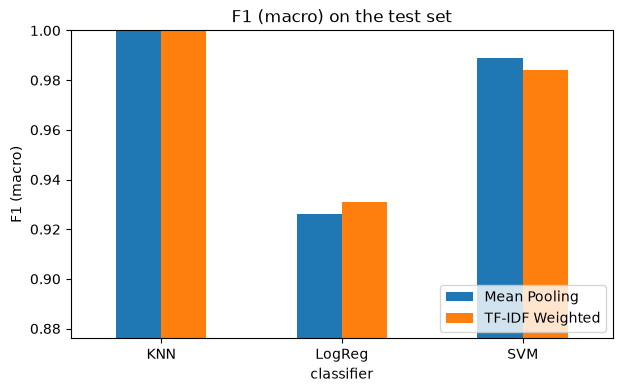

In [16]:
f1_table = results_df['F1 (macro)'].unstack(0)
f1_table.plot(kind='bar', figsize=(7, 4), rot=0)
plt.ylabel('F1 (macro)')
plt.ylim(f1_table.values.min() - 0.05, 1.0)
plt.title('F1 (macro) on the test set')
plt.legend(loc='lower right')
plt.show()

**Висновок.** Усі моделі працюють дуже добре. Найкращий KNN: на тесті він не помилився жодного разу, і це для обох
способів агрегації. Далі SVM (F1 = 0.989 для Mean Pooling і 0.984 для TF-IDF), найслабша LogReg (0.926 і 0.931).
TF-IDF трохи допоміг LogReg (ROC-AUC 0.969 -> 0.979) і трохи зашкодив SVM. Але в тесті всього 194 тексти, і кожна з цих
різниць - це одна помилка, тому великих висновків з них робити не варто. Чому числа такі високі, видно з t-SNE нижче:
датасет зібраний із шаблонів.

---
## 6. Етап 6. Візуалізація та аналіз

### 6.1 t-SNE

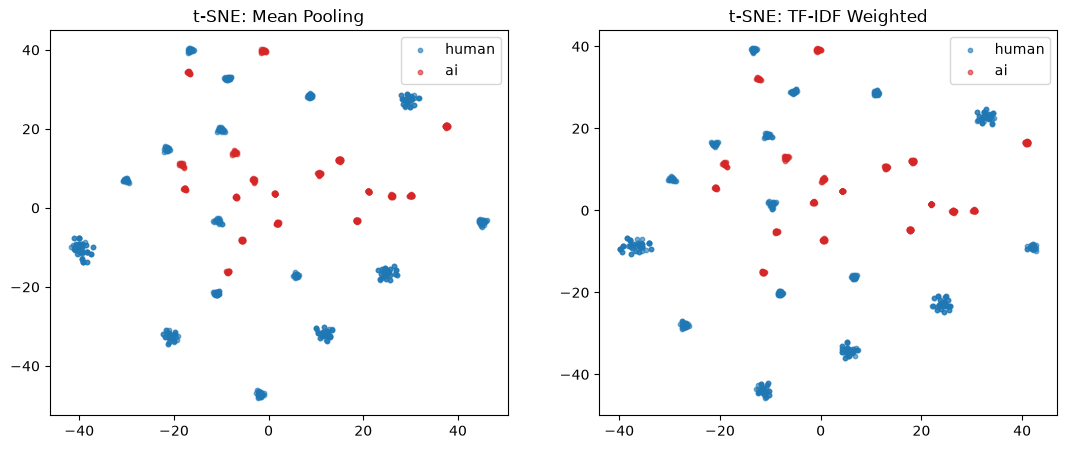

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (method, X) in zip(axes, [('Mean Pooling', X_mean), ('TF-IDF Weighted', X_tfidf)]):
    emb = TSNE(n_components=2, perplexity=30, random_state=42).fit_transform(X)
    for k, label, color in [(0, 'human', 'tab:blue'), (1, 'ai', 'tab:red')]:
        ax.scatter(emb[y == k, 0], emb[y == k, 1], s=10, alpha=0.6, color=color, label=label)
    ax.set_title(f't-SNE: {method}')
    ax.legend()
plt.show()

**Висновок.** На обох графіках видно приблизно 30 маленьких щільних "острівців", і кожен складається з текстів
одного класу. Це шаблони (ми бачили їх ще в етапі 1): одне й те саме речення, у яке підставили різні теми ("climate change",
"gene editing" тощо). Тому кожен клас не збирається в один великий кластер, а розпадається на багато дрібних.
Mean Pooling і TF-IDF дають майже однакову картину. Острівці лише розташовані по-різному, бо t-SNE щоразу
розставляє їх по-своєму.

### 6.2 Матриці плутанини

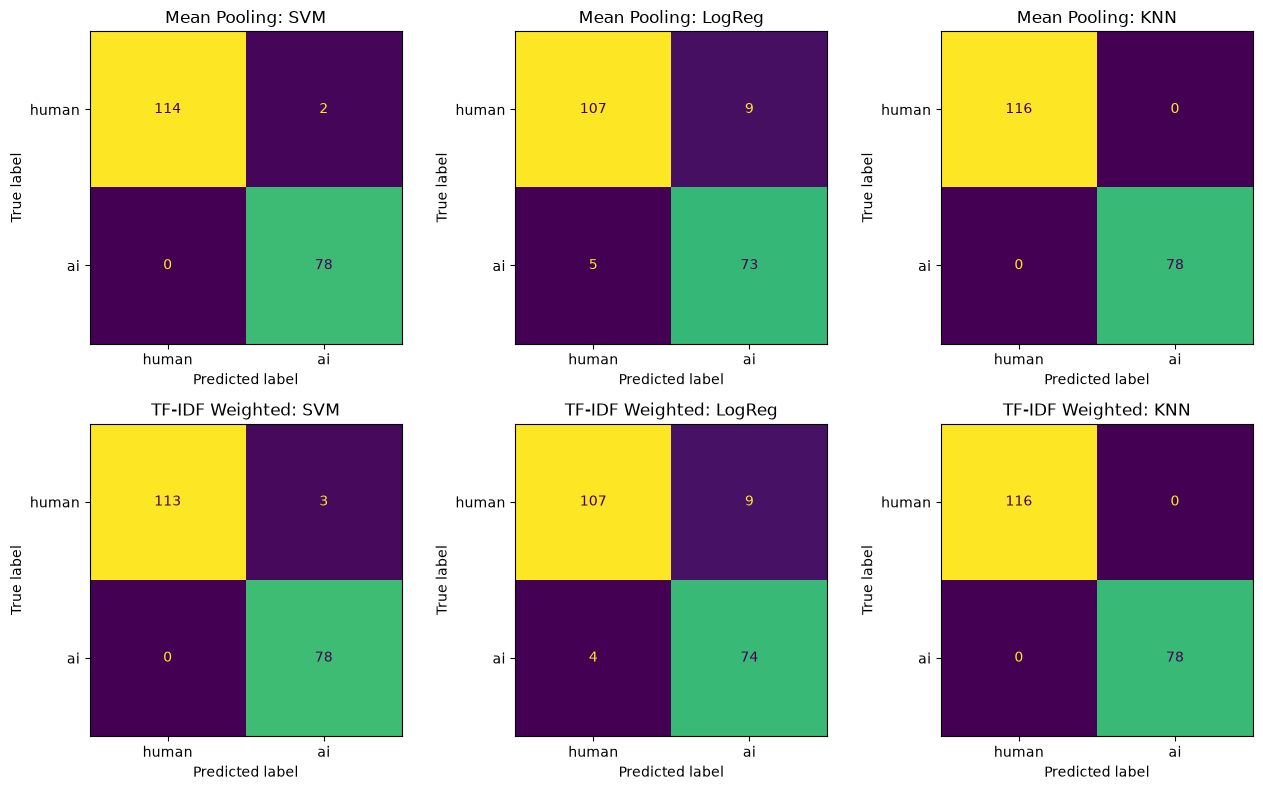

In [18]:
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for ax, ((method, name), y_pred) in zip(axes.ravel(), predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=['human', 'ai']).plot(ax=ax, colorbar=False)
    ax.set_title(f'{method}: {name}')
plt.tight_layout()
plt.show()

**Висновок.** SVM помиляється лише 2-3 рази, і завжди однаково: приймає людський текст за AI. LogReg
помиляється в обидва боки, але людський текст за AI-текст вважає частіше (9 разів для обох способів), ніж навпаки
(5 і 4). У KNN помилок немає. Для Mean Pooling і TF-IDF матриці майже однакові: різниця щонайбільше в одній помилці.

### 6.3 Геометрія векторного простору

Щоб відповісти на питання про геометрію, порахуємо кілька простих чисел для кожного способу:
- середня косинусна схожість між усіма парами документів (наскільки вектори "злиплись" в один напрямок);
- відстань між центрами класів;
- середній розкид точок навколо центру свого класу;
- відношення відстані між центрами до розкиду (чим більше, тим краще класи розходяться).

In [19]:
def geometry_stats(X, y):
    cos = cosine_similarity(X)
    pairs = cos[np.triu_indices_from(cos, k=1)]
    centers = [X[y == k].mean(axis=0) for k in [0, 1]]
    spread = np.mean([np.linalg.norm(X[y == k] - centers[k], axis=1).mean() for k in [0, 1]])
    dist = np.linalg.norm(centers[0] - centers[1])
    return {
        'mean cosine between docs': pairs.mean(),
        'distance between class centers': dist,
        'average spread inside class': spread,
        'centers distance / spread': dist / spread
    }

pd.DataFrame({'Mean Pooling': geometry_stats(X_mean, y),
              'TF-IDF Weighted': geometry_stats(X_tfidf, y)}).round(3)

,Mean Pooling,TF-IDF Weighted
mean cosine between docs,0.702,0.700
distance between class centers,0.543,0.553
average spread inside class,1.268,1.267
centers distance / spread,0.428,0.436


**Висновок.** Числа для обох способів майже однакові. Документи загалом дуже схожі між собою:
середня косинусна схожість ~0.70. TF-IDF трохи збільшує відстань між центрами класів (0.543 -> 0.553), а розкид усередині
класу не змінюється. Причина в тому, що тексти короткі (~22 токени після обробки) і **понад 99% слів трапляються в
документі лише один раз**. Тому вага TF-IDF майже повністю визначається IDF, а словник маленький (510 слів).
Ваги виходять досить схожими, і зважене середнє мало відрізняється від звичайного.

### 6.4 Слова з найбільшим TF-IDF для класу AI

Рахуємо середній TF-IDF кожного слова окремо по AI-текстах і по human-текстах. Перша таблиця - слова з найбільшим
TF-IDF в AI-текстах, друга - слова, у яких різниця "AI мінус human" найбільша (тобто найбільш "AI-шні").

In [20]:
words = pd.DataFrame({
    'word': tfidf_vocab,
    'TF-IDF (ai)': np.asarray(tfidf_matrix[y == 1].mean(axis=0)).ravel(),
    'TF-IDF (human)': np.asarray(tfidf_matrix[y == 0].mean(axis=0)).ravel()
})
words['difference'] = words['TF-IDF (ai)'] - words['TF-IDF (human)']

top_ai = words.sort_values('TF-IDF (ai)', ascending=False).head(15).reset_index(drop=True)
top_diff = words.sort_values('difference', ascending=False).head(15).reset_index(drop=True)
display(top_ai.round(4))
display(top_diff.round(4))

,word,TF-IDF (ai),TF-IDF (human),difference
0,challenge,0.0401,0.0220,0.0181
1,think,0.0350,0.0000,0.0350
2,conversation,0.0336,0.0100,0.0235
3,framework,0.0320,0.0131,0.0189
4,point,0.0304,0.0099,0.0205
5,expert,0.0300,0.0000,0.0300
6,development,0.0292,0.0000,0.0292
7,research,0.0285,0.0175,0.0110
8,solution,0.0284,0.0000,0.0284
9,underscore,0.0279,0.0000,0.0279


,word,TF-IDF (ai),TF-IDF (human),difference
0,think,0.0350,0.00,0.0350
1,expert,0.0300,0.00,0.0300
2,development,0.0292,0.00,0.0292
3,solution,0.0284,0.00,0.0284
4,underscore,0.0279,0.00,0.0279
5,stakeholder,0.0271,0.00,0.0271
6,follow,0.0260,0.00,0.0260
7,progress,0.0260,0.00,0.0260
8,recommendation,0.0254,0.00,0.0254
9,potential,0.0252,0.00,0.0252


In [21]:
# where do the most "AI-like" words appear?
for word in top_diff['word'][:5]:
    example = df.loc[df['tokens'].apply(lambda t: word in t) & (df['y'] == 1), 'text'].iloc[0]
    print(f'{word}: {example[:150]}...')

think: I've been thinking a lot about remote work productivity lately, and I think we need to have a more nuanced conversation about it. The polarization isn...
expert: New developments surrounding remote work productivity have drawn significant attention from analysts and policymakers alike. Experts suggest the impli...
development: Analysts are closely watching developments related to climate change adaptation strategies, noting that recent events mark a potential turning point. ...
solution: Analysts are closely watching developments related to climate change adaptation strategies, noting that recent events mark a potential turning point. ...
underscore: Analysts are closely watching developments related to climate change adaptation strategies, noting that recent events mark a potential turning point. ...


**Висновок.** Найбільш "AI-шні" слова: think, expert, development, solution, underscore, stakeholder,
progress, recommendation, potential, address, engage. У human-текстах вони не трапляються взагалі (TF-IDF = 0).
Частина з них справді схожа на типову лексику мовних моделей: underscore, stakeholder, address, engage,
recommendation, potential. Це якраз ті "канцеляризми", про які йдеться в гіпотезі. Але think, follow, open - це просто
слова з конкретних AI-шаблонів (наприклад, "I've been thinking a lot about..."). Тому в цьому датасеті такі слова
радше маркери шаблону, ніж AI-тексту взагалі.

---
## 7. Відповіді на дослідницькі питання

**1. Вплив агрегації.** TF-IDF дає рідкісним словам більшу вагу, а частим - меншу. Через це
вектор документа відходить від "загального центру", спільного для всіх текстів, у бік специфічних для документа слів.
Тут цей ефект дуже малий: середня косинусна схожість змінилась з 0.702 до 0.700, а відношення "відстань між центрами /
розкид" - з 0.428 до 0.436. Лінійна роздільність трохи покращилась: у лінійної LogReg F1 виріс з 0.926 до 0.931, а
ROC-AUC з 0.969 до 0.979. Покращення мале, бо тексти короткі, слова в документі майже не повторюються, а словник
маленький. Через це ваги TF-IDF не сильно відрізняються від рівних. Гіпотеза підтвердилась лише частково: напрям
правильний, але ефект на рівні однієї помилки в тесті, а в SVM навіть навпаки - на одну помилку більше.

**2. Порівняння класифікаторів.** Для обох способів агрегації порядок однаковий: KNN (1.000) > SVM (0.989 / 0.984) > LogReg
(0.926 / 0.931). Це відповідає структурі даних. Кожен клас складається з багатьох маленьких кластерів-шаблонів,
розкиданих по простору. Одна гіперплощина не може відділити всі "острівці" одного класу від усіх острівців іншого,
тому лінійна LogReg помиляється. RBF-SVM і KNN дивляться на локальну структуру і легко обводять кожен острівець.
Тобто дані добре роздільні, але нелінійно.

**3. Чутливість KNN.** У нас деградації немає: 1.000 і 1.000. Загалом вона можлива. KNN спирається тільки на
відстані, а TF-IDF може зробити вектор документа сильно залежним від 1-2 рідкісних слів. Тоді схожі за змістом тексти
опиняються далі один від одного, і відстані стають "шумнішими". До того ж у просторі розмірності 100 відстані між
точками стають схожими (прокляття розмірності), і навіть невелика зміна ваг може поміняти найближчих сусідів.
У нас цього не сталося, бо кожен тестовий текст має в train "родича" з того самого шаблону. Він відрізняється тільки
темою і за будь-якої агрегації лишається найближчим сусідом.

**4. Лінгвістична інтерпретація.** Див. 6.4. Найбільший TF-IDF для AI мають think, expert, development, solution,
underscore, stakeholder, progress, recommendation, potential, address, engage, і в human-текстах їх немає взагалі.
Слова на кшталт underscore, stakeholder, address, engage, recommendation можна вважати маркерами "офіційного" стилю
LLM. Але в цьому датасеті вони прив'язані до кількох шаблонів, тому це маркери конкретних шаблонів, а не
доведені ознаки будь-якого AI-тексту.

**5. Геометричний аналіз.** Так, на t-SNE класи утворюють компактні кластери, але не по одному на клас, а близько 30
дрібних однорідних кластерів (по одному на шаблон). Між способами агрегації візуальної різниці майже немає. За числами
з 6.3 TF-IDF розводить класи трохи краще (0.436 проти 0.428), але різниця дуже мала.

---
## Висновки

1. **Дані.** У датасеті 2 000 текстів, але 1 034 з них - дублікати. Після чистки лишилось 966 текстів
   (60% human / 40% ai). Тексти короткі (20-50 слів) і зібрані з шаблонів.
2. **Обробка.** spaCy: леми, без стоп-слів, тільки слова з букв. Після обробки словник має 510 слів, на документ
   припадає ~22 токени. FastText (100 вимірів, skip-gram) навчили на цьому корпусі.
3. **Результати.** F1 (macro): KNN - 1.000, SVM - 0.989 (Mean) / 0.984 (TF-IDF), LogReg - 0.926 / 0.931. Нелінійні методи
   кращі, бо класи складаються з багатьох дрібних кластерів.
4. **TF-IDF проти Mean Pooling.** Різниця майже непомітна: лінійна LogReg трохи виграє, SVM трохи
   програє (по одній помилці). Гіпотеза
   підтвердилась частково: на коротких текстах, де слова майже не повторюються, TF-IDF вага мало що змінює.
5. **Обмеження.** Датасет занадто простий: тестові тексти мають дуже близьких "родичів" із того самого шаблону в
   train. Тому високі метрики не означають, що модель упорається зі справжніми AI-текстами. Чесніше було б
   розбивати дані так, щоб шаблон цілком потрапляв або в train, або в test, чи взяти реалістичніший датасет.